# Exercise 4.3.30 (Peak Detection with ISTA)

Implement the ISTA from Example 4.3.24. For the signal $\hat x=(0,0,0,0,0,2,0,0,5,0,3,0)$ and the matrix $A=I$, generate data $y \sim A\hat x + \mathcal N(0,I_{12})$. Afterwards, run ISTA for this $y$. Count the number of zero-entries in the reconstruction $x$ depending on the parameter $\alpha$. 
Redo the same experiment with the Tikhonov functional $J_\alpha = \frac12\|Ax-y\|_2^2+\frac{\alpha}{2}\|x\|_2^2$ from (3.111) and count again the number of zero-entries for its minimizer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def FBS(x0, nu, grad, prox, loss, num_iter, it_thr = 0, xt = None):
    x = x0
    func_val = np.zeros((num_iter + 1))
    func_val[0] = loss(x0) 
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    for k in range(num_iter):
        # grad = A.T @( A @ x - y)
        x_old = x
        x = prox(x - nu* grad(x), nu)

        func_val[k+1] = loss(x)
        if xt is not None:
            error[k+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

        if it_thr > 0 and np.linalg.norm(x - x_old) < it_thr:
            break
    
    if xt is not None:
        return x, func_val, error
    else:
        return x, func_val

In [3]:
# Toy example data
N = 12
x_true = np.array([0,0,0,0,0, 2, 0, 0, 5, 0, 3, 0],dtype = float)
A = np.eye(N)
y = A @ x_true + np.random.randn(N)

x0 = np.random.randn(N)

alpha_list = 10.0**np.arange(-2,2,0.5)
X_Tikh = np.zeros((len(alpha_list), N))
X_Lasso = np.zeros((len(alpha_list), N))
num_iter = 100000

for ia in range(len(alpha_list)):    
    alph = alpha_list[ia]
     # Tikhonov
    grad = lambda x: A.T @( A @ x - y) + alph * x
    loss = lambda x: 0.5*np.linalg.norm(A@x - y)**2 + 0.5*alph * np.linalg.norm(x)**2
    prox = lambda x,nu: x
    nu = 1.0 / (1 + alph)
    
    x1, m_errors = FBS(x0, 0.9*nu, grad, prox, loss,num_iter, 1e-8)
    X_Tikh[ia,:] = x1
    
    # LASSO
    grad = lambda x: A.T @( A @ x - y)
    loss = lambda x: 0.5*np.linalg.norm(A@x - y)**2 + alph * np.linalg.norm(x,1)
    prox = lambda x,nu: np.sign(x)*np.maximum(np.abs(x) - nu*alph, 0)
    nu = 1.0 / np.linalg.norm(A,2)**2
    x2, m_errors = FBS(x0, 0.9*nu, grad, prox, loss,num_iter, 1e-8)
    X_Lasso[ia,:] = x2

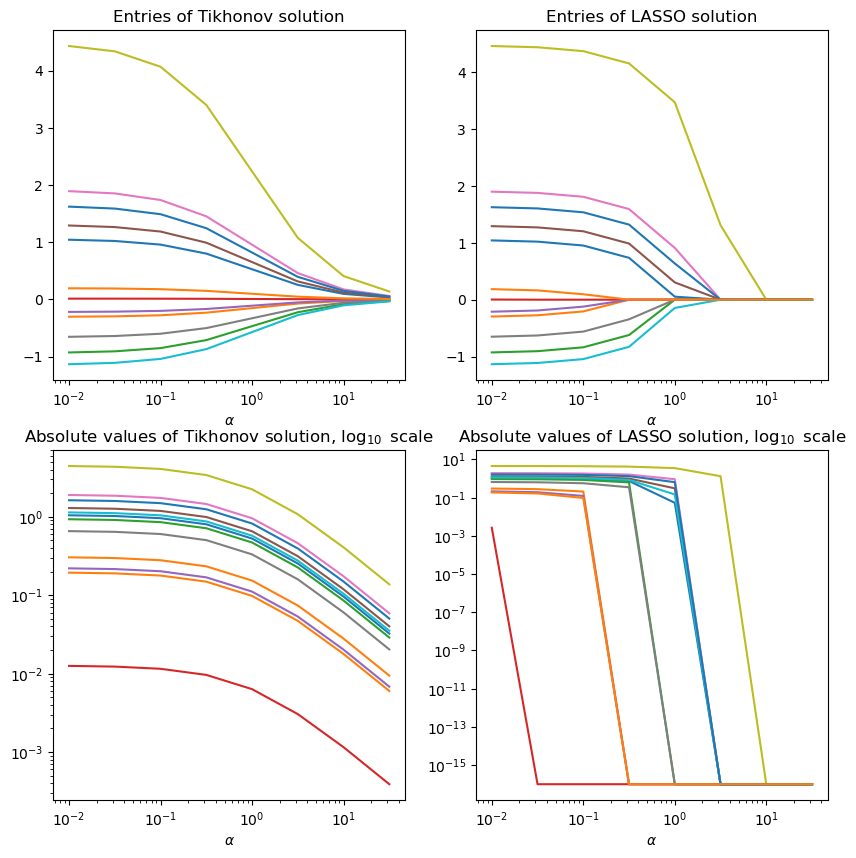

In [4]:
plt.figure(figsize=(5*2, 5*2))

plt.subplot(2, 2, 1)
plt.semilogx(alpha_list,X_Tikh)
plt.title(r'Entries of Tikhonov solution')
plt.xlabel(r"$\alpha$")

plt.subplot(2, 2, 2)
plt.semilogx(alpha_list,X_Lasso)
plt.title(r'Entries of LASSO solution')
plt.xlabel(r"$\alpha$")

plt.subplot(2, 2, 3)
plt.loglog(alpha_list,1e-16 + np.abs(X_Tikh))
plt.title(r'Absolute values of Tikhonov solution, $\log_{10}$ scale')
plt.xlabel(r"$\alpha$")

plt.subplot(2, 2, 4)
plt.loglog(alpha_list,1e-16 + np.abs(X_Lasso))
plt.title(r'Absolute values of LASSO solution, $\log_{10}$ scale')
plt.xlabel(r"$\alpha$")
plt.show()

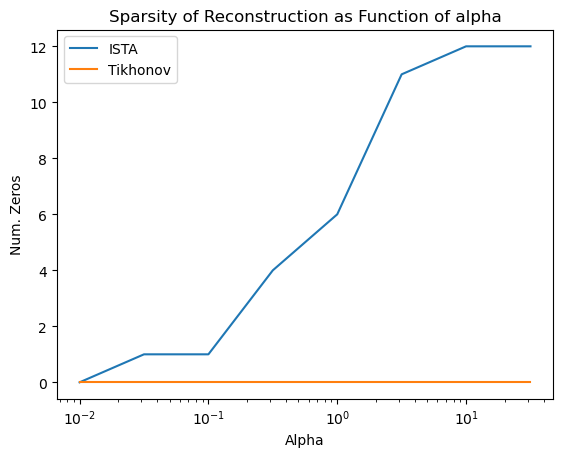

In [5]:
tol = 1e-6
num_zeros_tikhonov = np.sum(np.abs(X_Tikh) < tol,1)
num_zeros_ista = np.sum(np.abs(X_Lasso) < tol,1)

plt.semilogx(alpha_list, num_zeros_ista, label='ISTA')
plt.semilogx(alpha_list, num_zeros_tikhonov, label='Tikhonov')
plt.legend()
plt.xlabel('Alpha')
plt.ylabel('Num. Zeros')
plt.title('Sparsity of Reconstruction as Function of alpha')
plt.show()